In [5]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

BASE   = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"
LABELS = f"{BASE}/data/interim/muestra_genes_labels.tsv"
PROT   = f"{BASE}/data/interim/muestra_genes_prot.faa"
RES_A  = f"{BASE}/results/deeparg_genes_prot.mapping.ARG"   # proteina, identidad 50
RES_B  = f"{BASE}/results/deeparg_genes_id30.mapping.ARG"   # nucleotido, identidad 30

# ---------- Verdad de referencia ----------
truth = pd.read_csv(LABELS, sep="\t")
gid_col, lab_col = truth.columns[0], truth.columns[1]
truth = truth[[gid_col, lab_col]].rename(columns={gid_col:"gid", lab_col:"y_true"})
truth["y_true"] = truth["y_true"].astype(int)

# Clave corta = primer token del encabezado.
# DIAMOND y Prodigal cortan los encabezados en el primer espacio, asi que
# para cruzar resultados hay que usar exactamente esa misma forma recortada.
truth["key"] = truth["gid"].str.split().str[0]
print("Claves cortas unicas:", truth["key"].is_unique, "| genes:", len(truth))
# Si saliera False, la clave no distinguiria genes y el cruce seria invalido.

# ---------- Cobertura de Prodigal ----------
# Un gen sin ORF llamado no tiene proteina y se vuelve falso negativo automatico
# en la corrida A. Hay que saber cuantos son para poder declararlo.
prot_keys = set()
with open(PROT) as f:
    for ln in f:
        if ln.startswith(">"):
            # se quita el sufijo _N que agrega Prodigal para volver al id original
            prot_keys.add(ln[1:].split()[0].rsplit("_", 1)[0])
print(f"Genes con al menos un ORF de Prodigal: {truth['key'].isin(prot_keys).sum()}/{len(truth)}")

def evaluar(res_path, prodigal, titulo):
    """Evalua una salida .mapping.ARG de DeepARG contra la verdad de referencia.

    prodigal=True  -> la entrada paso por Prodigal: hay que QUITAR el sufijo _N.
    prodigal=False -> entrada nucleotidica con encabezados intactos: NO tocar.

    Esto no es cosmetico. Los negativos se llaman NC_000913.3_3449; si se les
    quitara el ultimo _N quedarian como NC_000913.3 y el cruce fallaria.
    """
    det = pd.read_csv(res_path, sep="\t")
    ids = det[det.columns[3]].astype(str)              # col 4 = identificador de la consulta
    if prodigal:
        ids = ids.str.rsplit("_", n=1).str[0]          # rsplit: corta por el ULTIMO guion bajo

    # Un gen presente en el archivo fue llamado ARG; uno ausente, no-ARG.
    y_pred = truth["key"].isin(set(ids.unique())).astype(int)

    print(f"\n=== {titulo} ===")
    print(f"Genes llamados ARG: {int(y_pred.sum())}")
    print(confusion_matrix(truth["y_true"], y_pred))   # filas = verdad, columnas = prediccion
    print(classification_report(truth["y_true"], y_pred,
          target_names=["no-ARG (0)", "ARG (1)"], digits=3))

evaluar(RES_A, True,  "A) LS --type prot (blastp), identidad 50")
evaluar(RES_B, False, "B) LS --type nucl (blastx), identidad 30")

print("\nReferencias:")
print("  DeepARG nucleotido, identidad 50 (por defecto) ->  recall_ARG = 0.351")
print("  Paper (comparacion publicada en ARGNet)        ->  recall = 0.842, precision = 1.000")

Claves cortas unicas: True | genes: 2000
Genes con al menos un ORF de Prodigal: 1993/2000

=== A) LS --type prot (blastp), identidad 50 ===
Genes llamados ARG: 352
[[998   2]
 [650 350]]
              precision    recall  f1-score   support

  no-ARG (0)      0.606     0.998     0.754      1000
     ARG (1)      0.994     0.350     0.518      1000

    accuracy                          0.674      2000
   macro avg      0.800     0.674     0.636      2000
weighted avg      0.800     0.674     0.636      2000


=== B) LS --type nucl (blastx), identidad 30 ===
Genes llamados ARG: 736
[[984  16]
 [280 720]]
              precision    recall  f1-score   support

  no-ARG (0)      0.778     0.984     0.869      1000
     ARG (1)      0.978     0.720     0.829      1000

    accuracy                          0.852      2000
   macro avg      0.878     0.852     0.849      2000
weighted avg      0.878     0.852     0.849      2000


Referencias:
  DeepARG nucleotido, identidad 50 (por defecto)

 identidad_%  llamados_ARG  recall  precision    f1  accuracy
          20           785   0.760      0.968 0.852     0.868
          30           736   0.720      0.978 0.829     0.852
          40           525   0.516      0.983 0.677     0.754
          50           353   0.351      0.994 0.519     0.674
          60           292   0.292      1.000 0.452     0.646
          70           246   0.246      1.000 0.395     0.623


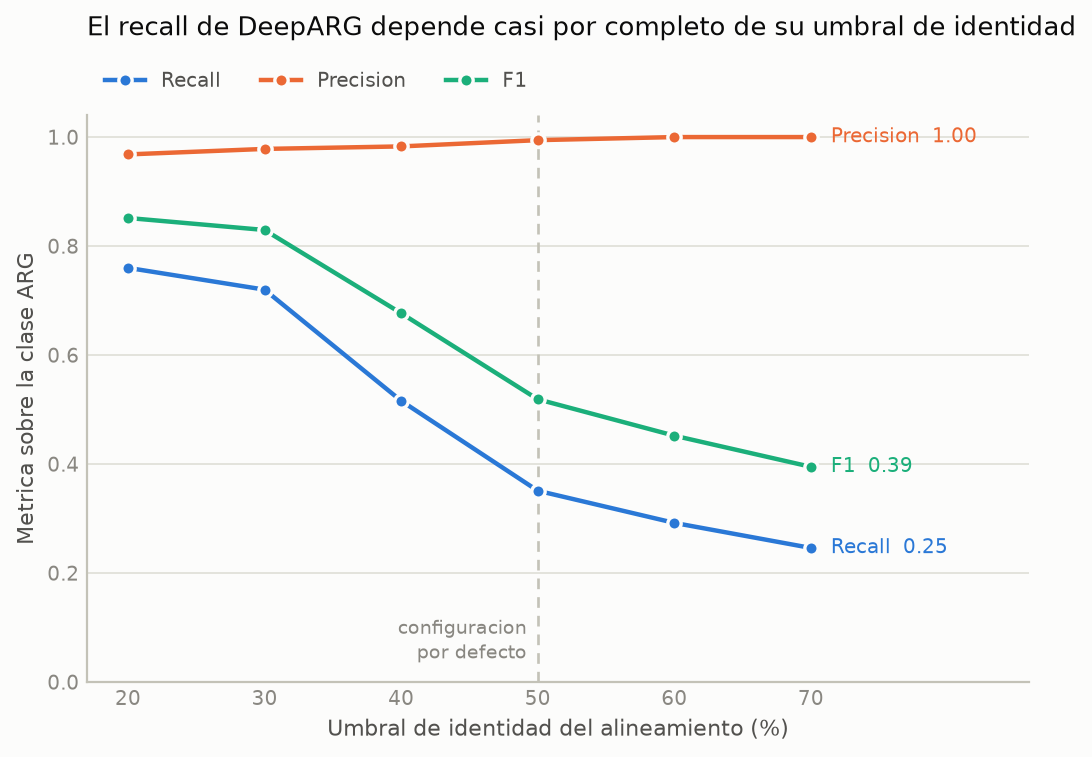

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

BASE     = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"
LABELS   = f"{BASE}/data/interim/muestra_genes_labels.tsv"
UMBRALES = [20, 30, 40, 50, 60, 70]

truth = pd.read_csv(LABELS, sep="\t")
gid_col, lab_col = truth.columns[0], truth.columns[1]
truth = truth[[gid_col, lab_col]].rename(columns={gid_col:"gid", lab_col:"y_true"})
truth["y_true"] = truth["y_true"].astype(int)
truth["key"] = truth["gid"].str.split().str[0]

filas = []
for idv in UMBRALES:
    det = pd.read_csv(f"{BASE}/results/deeparg_id{idv}.mapping.ARG", sep="\t")
    # entrada nucleotidica: los encabezados llegan intactos, NO se quita sufijo
    ids = set(det[det.columns[3]].astype(str).unique())
    y_pred = truth["key"].isin(ids).astype(int)
    p, r, f, _ = precision_recall_fscore_support(truth["y_true"], y_pred,
                                                 labels=[1], average=None)
    filas.append({"identidad_%": idv,
                  "llamados_ARG": int(y_pred.sum()),
                  "recall": r[0], "precision": p[0], "f1": f[0],
                  "accuracy": accuracy_score(truth["y_true"], y_pred)})

tabla = pd.DataFrame(filas)
print(tabla.round(3).to_string(index=False))
tabla.to_csv(f"{BASE}/results/curva_deeparg_identidad.csv", index=False)

# ---------- Figura ----------
# Tokens de color: fondo, tinta principal, tinta secundaria, apagado, rejilla, ejes
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLS = {"recall": "#2a78d6", "precision": "#eb6834", "f1": "#1baf7a"}   # paleta validada para daltonismo
ETIQ = {"recall": "Recall", "precision": "Precision", "f1": "F1"}

fig, ax = plt.subplots(figsize=(7.6, 4.6), dpi=160)
fig.patch.set_facecolor(SURF); ax.set_facecolor(SURF)

# linea de referencia en el valor por defecto de la herramienta
ax.axvline(50, color=AXIS, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(49.2, 0.03, "configuracion\npor defecto", color=MUTED, fontsize=8.5,
        ha="right", va="bottom", linespacing=1.3)

for m in ["recall", "precision", "f1"]:
    ax.plot(tabla["identidad_%"], tabla[m], color=COLS[m], lw=2,
            marker="o", ms=6, mec=SURF, mew=1.5, zorder=3, label=ETIQ[m])
    # etiqueta directa al final de cada linea: el color no es el unico portador del dato
    ax.annotate(f"{ETIQ[m]}  {tabla[m].iloc[-1]:.2f}",
                (tabla["identidad_%"].iloc[-1], tabla[m].iloc[-1]),
                textcoords="offset points", xytext=(9, 0),
                ha="left", va="center", color=COLS[m], fontsize=9)

ax.set_xlim(17, 86); ax.set_ylim(0, 1.04)
ax.set_xticks(UMBRALES)
ax.set_xlabel("Umbral de identidad del alineamiento (%)", color=INK2, fontsize=10)
ax.set_ylabel("Metrica sobre la clase ARG", color=INK2, fontsize=10)
ax.set_title("El recall de DeepARG depende casi por completo de su umbral de identidad",
             color=INK, fontsize=11.5, loc="left", pad=36)

ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)   # rejilla detras de los datos
for s in ("top", "right"): ax.spines[s].set_visible(False)      # marco minimo
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS); ax.spines[s].set_linewidth(1)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
          frameon=False, fontsize=9, labelcolor=INK2)

plt.savefig(f"{BASE}/results/fig_deeparg_identidad.png",  dpi=300, facecolor=SURF, bbox_inches="tight")
plt.savefig(f"{BASE}/results/fig_deeparg_identidad.tiff", dpi=300, facecolor=SURF, bbox_inches="tight")
plt.show()

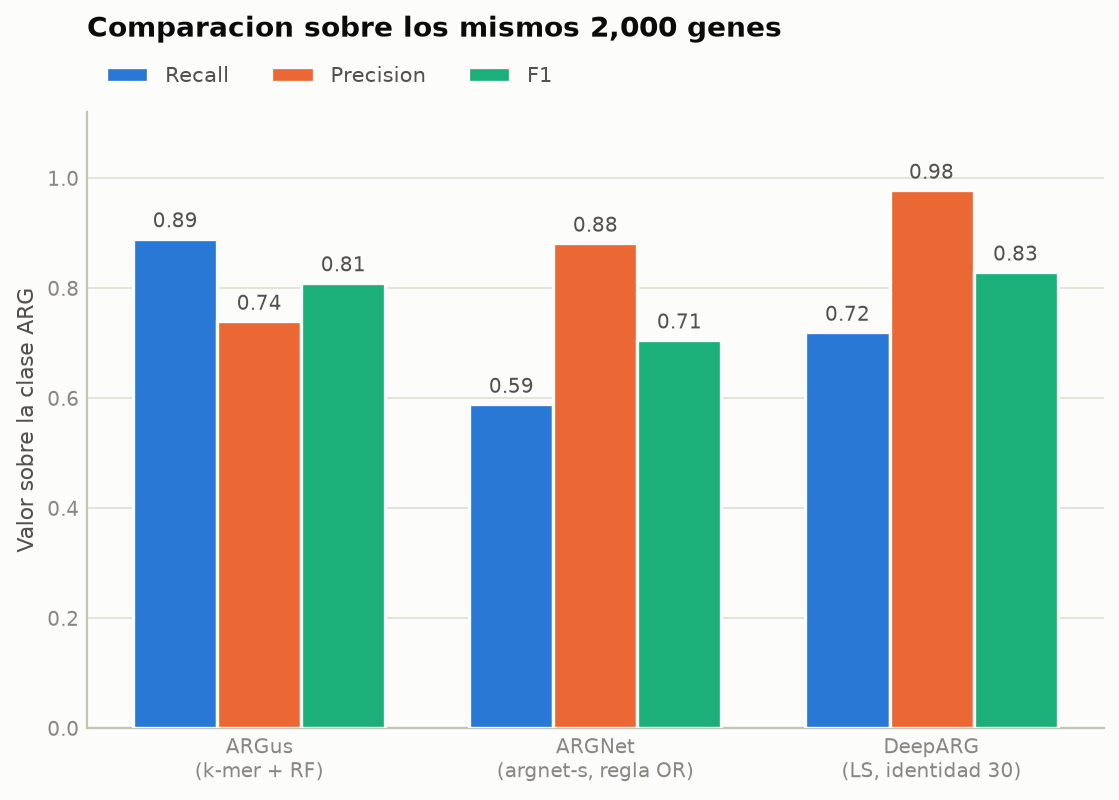

                             Recall  Precision     F1
ARGus (k-mer + RF)            0.890      0.740  0.810
ARGNet (argnet-s, regla OR)   0.589      0.882  0.706
DeepARG (LS, identidad 30)    0.720      0.978  0.829


In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"

# DeepARG se toma del barrido de la celda anterior, en lugar de teclear los numeros a mano
curva = pd.read_csv(f"{BASE}/results/curva_deeparg_identidad.csv").set_index("identidad_%")
dp30 = curva.loc[30]

# ---- EDITA AQUI si tus cifras cambian ----
ARGUS  = (0.890, 0.740, 0.810)   # recall, precision, f1  <- confirmar la procedencia
ARGNET = (0.589, 0.882, 0.706)   # argnet-s, lecturas de 150 nt, agregado a gen con regla OR

modelos = [
    ("ARGus\n(k-mer + RF)",           *ARGUS),
    ("ARGNet\n(argnet-s, regla OR)",  *ARGNET),
    ("DeepARG\n(LS, identidad 30)",   dp30["recall"], dp30["precision"], dp30["f1"]),
]

nombres = [m[0] for m in modelos]
datos = {"Recall":    [m[1] for m in modelos],
         "Precision": [m[2] for m in modelos],
         "F1":        [m[3] for m in modelos]}

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLS = {"Recall": "#2a78d6", "Precision": "#eb6834", "F1": "#1baf7a"}

x = np.arange(len(nombres))   # una posicion por modelo
w = 0.25                      # ancho de cada barra; 3 barras por grupo

fig, ax = plt.subplots(figsize=(8.2, 5.0), dpi=160)
fig.patch.set_facecolor(SURF); ax.set_facecolor(SURF)

for i, (met, vals) in enumerate(datos.items()):
    # (i-1)*w desplaza las tres barras alrededor del centro del grupo
    barras = ax.bar(x + (i - 1) * w, vals, w, label=met, color=COLS[met],
                    edgecolor=SURF, linewidth=1.5, zorder=3)  # borde del color del fondo = separacion
    ax.bar_label(barras, fmt="%.2f", padding=3, fontsize=9, color=INK2)  # valor sobre cada barra

ax.set_xticks(x)
ax.set_xticklabels(nombres, fontsize=10, color=INK2)
ax.set_ylim(0, 1.12)          # holgura arriba para que quepan las etiquetas
ax.set_ylabel("Valor sobre la clase ARG", color=INK2, fontsize=10)
ax.set_title("Comparacion sobre los mismos 2,000 genes",
             color=INK, fontsize=12.5, loc="left", pad=34, fontweight="bold")

ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS); ax.spines[s].set_linewidth(1)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
          frameon=False, fontsize=9.5, labelcolor=INK2)

plt.savefig(f"{BASE}/results/fig_comparacion_modelos.png",  dpi=300, facecolor=SURF, bbox_inches="tight")
plt.savefig(f"{BASE}/results/fig_comparacion_modelos.tiff", dpi=300, facecolor=SURF, bbox_inches="tight")
plt.show()

print(pd.DataFrame(datos, index=[n.replace("\n", " ") for n in nombres]).round(3).to_string())